# NewsBot Intelligence System | ITAI 2373 Midterm

**Submission type:** Individual GitHub portfolio copy of the midterm project  
**Student:** Idris O Junaid
**Course:** ITAI 2373 Natural Language Processing  
**Portfolio repository:**
https://github.com/IdrisJunaidAI/ITAI2373_NewsBot_Midterm

**Dataset:** Instructor approved BBC News Classification training articles, Kaggle  
**Scope:** Five BBC categories: business, entertainment, politics, sport, tech  

**Research question:** Can an interpretable, computationally efficient NLP pipeline accurately classify English language news while extracting linguistic patterns, sentiment and named entities?

**Submission integrity:** The professor approved the BBC dataset. The notebook uses the genuine labeled BBC training file after upload. Model results and graphics are calculated during execution and must not be represented as completed unless the notebook has been run. The individual author must review interpretations and identify their real contribution to any group work.


## 1 | Business case and analytical design

NewsBot targets editors, research analysts and corporate intelligence teams. Its outputs support article routing, topic surveillance, media tone tracking and entity based search. Humans should review sensitive content, especially political, medical or financial stories. The system is intended for English articles of substantial length, not headlines alone. A classification model is trained on category labels; sentiment is an independent lexical estimate, not a factual reliability assessment.

**Method:** validate dataset provenance, preprocess a dedicated modeling copy, fit vectorizers inside model pipelines after splitting data, evaluate multiple estimators, analyze POS and syntax using original text, extract named entities, and demonstrate inference on previously unseen examples. Leakage prevention and training inference parity are explicit design constraints.

## 2 | Dataset, execution and provenance

**Approved dataset:** [BBC News Classification Kaggle competition](https://www.kaggle.com/competitions/learn-ai-bbc/data). The competition provides **1,490 labeled training articles** and a separate unlabeled competition test file. Download `BBC News Train.csv` from Kaggle after accepting the relevant terms. This analysis builds its own stratified held out test set from the 1,490 labeled articles; it does not report results on the unlabeled competition set.

**To run:** In Google Colab, select Runtime, Run all, and upload `BBC News Train.csv` when prompted. The original columns are usually `ArticleId`, `Text` or `Article`, and `Category`; the loader supports both text variants. The full article, original case, is retained for NER, POS tagging, syntax and sentiment. TF IDF modeling uses the raw text within a fitted scikit learn pipeline to avoid inconsistent transformations and leakage. The separate lemmatized view is used for exploratory term analysis.


In [ ]:
# Preserve Colab's preinstalled scientific packages.
%pip -q install vaderSentiment
import sys, subprocess, spacy
if not spacy.util.is_package("en_core_web_sm"):
    subprocess.check_call([sys.executable, "-m", "spacy", "download", "en_core_web_sm"])
print("Dependencies ready")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 2.2 MB/s eta 0:00:00
Dependencies ready


In [ ]:
import re, html, json, warnings
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt, spacy
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.dummy import DummyClassifier
nlp=spacy.load("en_core_web_sm")
sia=SentimentIntensityAnalyzer()
SEED=42
np.random.seed(SEED)

## 3 | Dataset loading, quality assurance and audit

Expected input: CSV with a label column (`category`, `Category`, `label`) and substantial article body (`text`, `Text`, `content`, `article`, `description`). If a title column is present it is incorporated. The default dataset is **not included in this download**, because its license/access and instructor approval need verification.

Upload your instructor approved dataset CSV


Saving BBC News Train.csv to BBC News Train.csv
Input shape: (1490, 3) Missing values: {'category': 0, 'content': 0, 'title': 0}
Accepted dataset: BBC News Train.csv Total: 1440 Classes: {'sport': 342, 'business': 335, 'politics': 266, 'entertainment': 263, 'tech': 234}
DATASET STRUCTURE VALIDATED. Instructor approval confirmed by student; confirm English language and dataset provenance.


,category,title,content
0,business,,worldcom ex-boss launches defence lawyers defe...
1,business,,german business confidence slides german busin...
2,business,,bbc poll indicates economic gloom citizens in ...


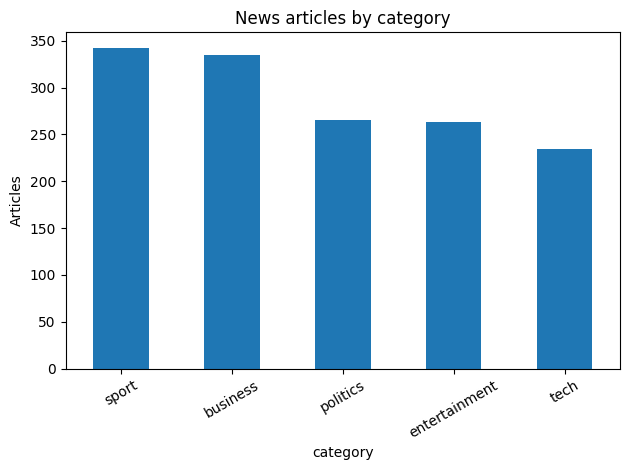

In [ ]:
candidates = [Path("BBC News Train.csv"), Path("bbc-news-train.csv"), Path("train.csv"), Path("newsbot_dataset.csv")]
file_path = next((p for p in candidates if p.exists()), None)
if file_path is None:
    try:
        from google.colab import files
        print("Upload your instructor approved dataset CSV")
        uploaded=files.upload()
        file_path=Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError("Place an instructor approved CSV beside this notebook, then rerun.")
raw=pd.read_csv(file_path)
name_map={c.lower().strip():c for c in raw.columns}
label_col=next((name_map[k] for k in ('category','label','class') if k in name_map),None)
body_col=next((name_map[k] for k in ('text','article','content','body','description') if k in name_map),None)
title_col=next((name_map[k] for k in ('title','headline') if k in name_map),None)
if not label_col or not body_col: raise ValueError(f"Expected category and full article text. Found: {raw.columns.tolist()}")
df=pd.DataFrame({'category':raw[label_col], 'content':raw[body_col]})
df['title']=raw[title_col] if title_col else ''
print('Input shape:',raw.shape,'Missing values:',df.isna().sum().to_dict())
df=df.dropna(subset=['category','content']).copy()
df['content']=df['content'].astype(str).str.strip()
df['category']=df['category'].astype(str).str.strip()
df['title']=df['title'].fillna('').astype(str).str.strip()
df=df[(df.content.str.len() >= 160)&(df.category!='')].drop_duplicates(subset=['content']).copy()
if len(df)>2000:
    df=df.sample(n=2000,random_state=SEED).copy()
df=df.reset_index(drop=True)
df['article_id']=np.arange(1,len(df)+1)
df['full_text']=(df['title']+' '+df['content']).str.strip()
counts=df.category.value_counts()
print('Accepted dataset:',file_path,'Total:',len(df),'Classes:',counts.to_dict())
assert len(df)>=500, 'Dataset needs at least 500 qualifying articles'
assert len(counts)>=4, 'Dataset needs at least four categories'
assert counts.min()>=5, 'Each class needs at least five examples'
assert len(df)<=2000 and df.full_text.notna().all()
assert df.content.str.len().min()>=160
print('DATASET STRUCTURE VALIDATED. Instructor approval confirmed by student; confirm English language and dataset provenance.')
display(df[['category','title','content']].head(3))
df.category.value_counts().plot.bar(title='News articles by category',rot=30);plt.ylabel('Articles');plt.tight_layout();plt.show()

## 4 | Module 2: Text cleaning and tokenization

Only the modeling view is lowercased, lemmatized and stripped of most punctuation. Original capitalization and syntax remain available for NER and dependency parsing. Emails and URLs are converted to semantic placeholders rather than broken into misleading fragments. Negation terms remain available because they can affect meaning.

In [ ]:
def normalize_markup(text):
    text=html.unescape(str(text))
    text=re.sub(r'<[^>]*>',' ',text)
    text=re.sub(r'[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}',' EMAILTOKEN ',text)
    text=re.sub(r'https?://\S+|www\.\S+',' URLTOKEN ',text)
    text=re.sub(r'\s+',' ',text).strip()
    return text

def preprocess_docs(texts):
    cleaned=[normalize_markup(t) for t in texts]
    out=[]
    for doc in nlp.pipe(cleaned,batch_size=48):
        words=[t.lemma_.lower() for t in doc if (t.is_alpha or t.text.lower() in ('urltoken','emailtoken')) and (not t.is_stop or t.lower_ in {'no','not','never'}) and len(t.text)>1]
        out.append(' '.join(words))
    return out

df['processed']=preprocess_docs(df.full_text.tolist())
print('Before:',df.full_text.iloc[0][:250]);print('After:',df.processed.iloc[0][:250])
print('Mean tokens before:',round(df.full_text.str.split().str.len().mean(),1),'after:',round(df.processed.str.split().str.len().mean(),1))

Before: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  cynthia cooper  worldcom s ex-head of internal accounting  alerted
After: worldcom ex boss launch defence lawyer defend worldcom chief bernie ebber battery fraud charge call company whistleblow witness cynthia cooper worldcom ex head internal accounting alert director irregular accounting practice telecom giant warning lea
Mean tokens before: 385.2 after: 196.7


## 5 | Module 3: TF IDF features and category terms

A descriptive TF IDF model below is fitted only to inspect category language. The **classification** vectorizer is fit separately, strictly within training folds. Terms with the largest mean TF IDF weights are descriptive, not causal explanations.

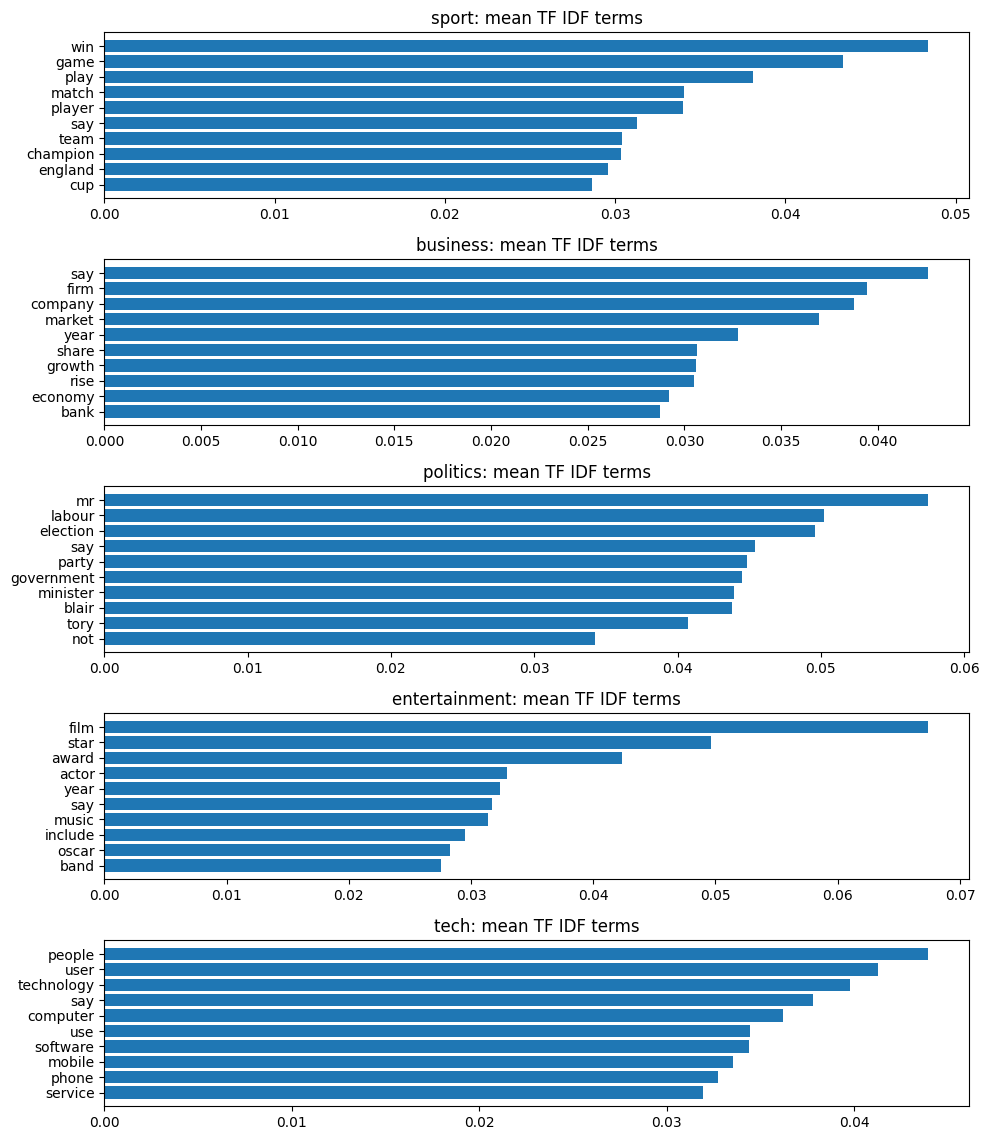

In [ ]:
descriptive_vec=TfidfVectorizer(ngram_range=(1,2),min_df=2,max_df=.95,max_features=4500,sublinear_tf=True)
D=descriptive_vec.fit_transform(df.processed)
terms=np.array(descriptive_vec.get_feature_names_out())
fig,axes=plt.subplots(len(counts),1,figsize=(10,2.3*len(counts)))
axes=np.atleast_1d(axes)
for ax,(cat,ncat) in zip(axes,counts.items()):
    weights=np.asarray(D[df.category.eq(cat).to_numpy()].mean(axis=0)).ravel()
    top=np.argsort(weights)[-10:]
    ax.barh(terms[top],weights[top]);ax.set_title(f'{cat}: mean TF IDF terms')
plt.tight_layout();plt.show()

## 6 | Module 4: POS tagging and editorial style

POS proportions are computed from original articles, omitting spaces and punctuation. Differences suggest variation in writing styles but can also arise from article lengths, publishers and sampling.

,NOUN,PROPN,VERB,ADJ,ADV,NUM,PRON
category,,,,,,,
business,0.253,0.082,0.124,0.080,0.031,0.039,0.039
entertainment,0.250,0.099,0.122,0.074,0.029,0.034,0.056
politics,0.234,0.080,0.137,0.076,0.031,0.018,0.062
sport,0.208,0.106,0.128,0.071,0.037,0.033,0.078
tech,0.261,0.050,0.135,0.084,0.038,0.025,0.056


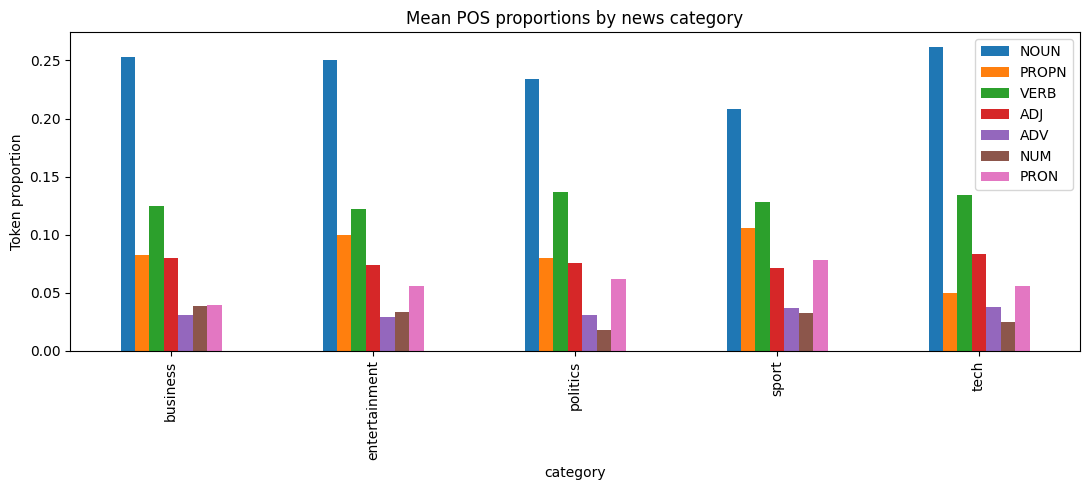

In [ ]:
docs=list(nlp.pipe(df.full_text.tolist(),batch_size=40))
pos_rows=[]
for doc in docs:
    valid=[t.pos_ for t in doc if not t.is_punct and not t.is_space]
    c=Counter(valid);total=max(len(valid),1)
    pos_rows.append({p:c[p]/total for p in ['NOUN','PROPN','VERB','ADJ','ADV','NUM','PRON']})
pos_frame=pd.DataFrame(pos_rows).fillna(0)
pos_mean=pos_frame.assign(category=df.category).groupby('category').mean()
display(pos_mean.round(3))
pos_mean.plot.bar(figsize=(11,5),title='Mean POS proportions by news category');plt.ylabel('Token proportion');plt.tight_layout();plt.show()

## 7 | Module 5: Dependency parsing and semantic roles

The subject verb object extractor below is a **syntactic approximation** to semantic roles, not a complete semantic role labeling model. Passive voice, coreference and complex clauses require more advanced processing.

In [ ]:
def extract_relations(doc,limit=8):
    triples=[]
    for verb in doc:
        if verb.pos_!='VERB':continue
        subs=[x for x in verb.children if x.dep_ in ('nsubj','nsubjpass','csubj')]
        objs=[x for x in verb.children if x.dep_ in ('dobj','obj','attr','oprd','dative')]
        for s in subs[:2]:
            for o in objs[:2]:
                triples.append({'subject':s.text,'action':verb.lemma_,'object':o.text,'voice':'passive' if s.dep_=='nsubjpass' else 'active'})
                if len(triples)>=limit:return triples
    return triples

df['relation_count']=[len(extract_relations(doc)) for doc in docs]
example_idx=next((i for i,d in enumerate(docs) if extract_relations(d)),0)
print('Sample sentence:',next(iter(docs[example_idx].sents)).text[:400])
display(pd.DataFrame(extract_relations(docs[example_idx])))
print('Mean extracted relations per article:',round(df.relation_count.mean(),2))

Sample sentence: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  


,subject,action,object,voice
0,-,launch,lawyers,active
1,boss,launch,lawyers,active
2,s,alert,directors,active
3,ebbers,orchestrate,series,active
4,who,run,business,active
5,cooper,tell,jury,active
6,andersen,approve,accounting,active
7,andersen,give,light,active


Mean extracted relations per article: 7.26


## 8 | Module 6: Sentiment and emotion proxies

VADER provides positive, neutral and negative **lexicon scores**. It does not reliably establish emotions such as fear or joy. A transparent emotional vocabulary proxy is included as exploratory analysis only and must not be presented as a validated emotion classifier.

sentiment_label,negative,neutral,positive
category,,,
business,0.361,0.012,0.627
entertainment,0.179,0.015,0.806
politics,0.462,0.004,0.534
sport,0.199,0.003,0.798
tech,0.214,0.009,0.778


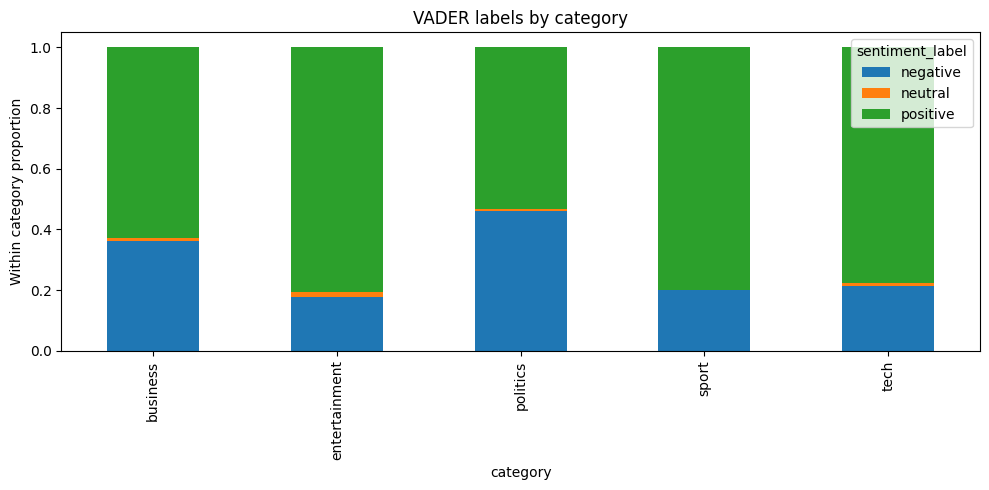

,proxy_fear,proxy_joy,proxy_anger,proxy_sadness
category,,,,
business,0.328,0.218,0.045,0.197
entertainment,0.133,1.471,0.087,0.202
politics,0.414,0.515,0.124,0.094
sport,0.132,2.026,0.041,0.108
tech,0.333,0.355,0.009,0.068


In [ ]:
sent=pd.DataFrame([sia.polarity_scores(x) for x in df.full_text])
df['sentiment_score']=sent['compound']
df['sentiment_label']=np.select([df.sentiment_score>=.05,df.sentiment_score<=-.05],['positive','negative'],default='neutral')
emotion_lex={'fear':{'fear','threat','risk','danger','crisis'},'joy':{'celebrate','success','win','delight','hope'},'anger':{'anger','outrage','protest','furious','condemn'},'sadness':{'grief','loss','death','mourning','tragic'}}
for label,words in emotion_lex.items():
    df['proxy_'+label]=[sum(t.lemma_.lower() in words for t in doc) for doc in docs]
display(pd.crosstab(df.category,df.sentiment_label,normalize='index').round(3))
pd.crosstab(df.category,df.sentiment_label,normalize='index').plot.bar(stacked=True,figsize=(10,5),title='VADER labels by category');plt.ylabel('Within category proportion');plt.tight_layout();plt.show()
display(df.groupby('category')[[f'proxy_{x}' for x in emotion_lex]].mean().round(3))

## 9 | Module 7: Fair multiclass classification and evaluation

Train/test split is stratified and fixed before any classifier vocabulary is fitted. Three estimators and a majority baseline are evaluated, macro F1 and accuracy are reported, and hyperparameters are selected by cross validation **within training data only**. Final test evaluation is performed once, after selecting by cross validation, to reduce test selection bias.

,model,cv_accuracy,cv_macro_f1,cv_f1_std
3,Linear SVM,0.9705,0.9694,0.0130
2,Logistic Regression,0.9627,0.9615,0.0087
1,Multinomial NB,0.9549,0.9534,0.0133
0,Majority baseline,0.2378,0.0769,0.0003


Selected by CV macro F1: Linear SVM
Held out accuracy: 0.9653 Held out macro F1: 0.9645
               precision    recall  f1-score   support

     business       0.94      0.97      0.96        67
entertainment       1.00      0.98      0.99        53
     politics       0.98      0.96      0.97        53
        sport       0.94      1.00      0.97        68
         tech       0.98      0.89      0.93        47

     accuracy                           0.97       288
    macro avg       0.97      0.96      0.96       288
 weighted avg       0.97      0.97      0.97       288



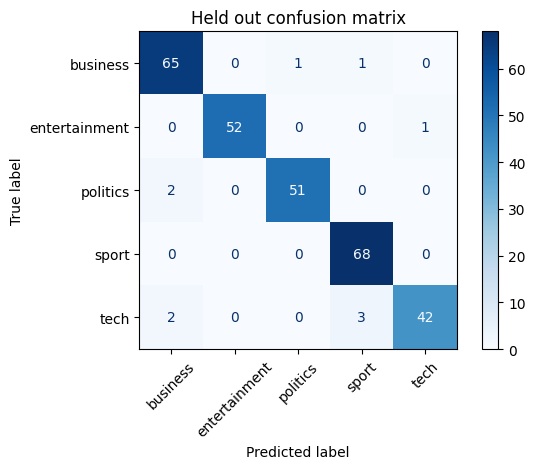

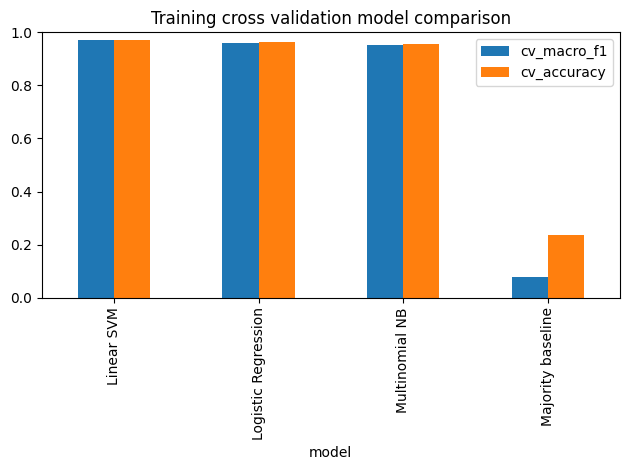

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(df.full_text,df.category,test_size=.2,random_state=SEED,stratify=df.category)
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
models={
 'Majority baseline':Pipeline([('vec',TfidfVectorizer(max_features=5000)),('clf',DummyClassifier(strategy='most_frequent'))]),
 'Multinomial NB':Pipeline([('vec',TfidfVectorizer(stop_words='english',ngram_range=(1,2),min_df=2,max_features=12000)),('clf',MultinomialNB())]),
 'Logistic Regression':Pipeline([('vec',TfidfVectorizer(stop_words='english',ngram_range=(1,2),min_df=2,max_features=12000)),('clf',LogisticRegression(max_iter=1500,random_state=SEED))]),
 'Linear SVM':Pipeline([('vec',TfidfVectorizer(stop_words='english',ngram_range=(1,2),min_df=2,max_features=12000)),('clf',LinearSVC(random_state=SEED))])}
cv_results=[]
for name,pipe in models.items():
    scores=cross_validate(pipe,X_train,y_train,cv=cv,scoring={'accuracy':'accuracy','f1_macro':'f1_macro'},n_jobs=1)
    cv_results.append({'model':name,'cv_accuracy':scores['test_accuracy'].mean(),'cv_macro_f1':scores['test_f1_macro'].mean(),'cv_f1_std':scores['test_f1_macro'].std()})
comparison=pd.DataFrame(cv_results).sort_values('cv_macro_f1',ascending=False)
display(comparison.round(4))
selected_name=comparison.iloc[0]['model']
print('Selected by CV macro F1:',selected_name)
selected_model=clone(models[selected_name])
selected_model.fit(X_train,y_train)
y_pred=selected_model.predict(X_test)
print('Held out accuracy:',round(accuracy_score(y_test,y_pred),4),'Held out macro F1:',round(f1_score(y_test,y_pred,average='macro'),4))
print(classification_report(y_test,y_pred,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,xticks_rotation=45,cmap='Blues');plt.title('Held out confusion matrix');plt.tight_layout();plt.show()
comparison.set_index('model')[['cv_macro_f1','cv_accuracy']].plot.bar(title='Training cross validation model comparison',ylim=(0,1));plt.tight_layout();plt.show()

## 10 | Module 8: Named entity recognition and relationship mapping

spaCy entity labels can be imperfect, particularly for specialized or ambiguous organizations. Entity cooccurrence in a story is a weak association, **not** evidence of a direct relationship.

type,DATE,GPE,MONEY,ORG,PERSON
category,,,,,
business,2398,1543,906,1392,974
entertainment,1672,773,343,632,1794
politics,1322,933,222,584,1884
sport,1966,1482,43,673,2504
tech,1165,702,196,1007,646


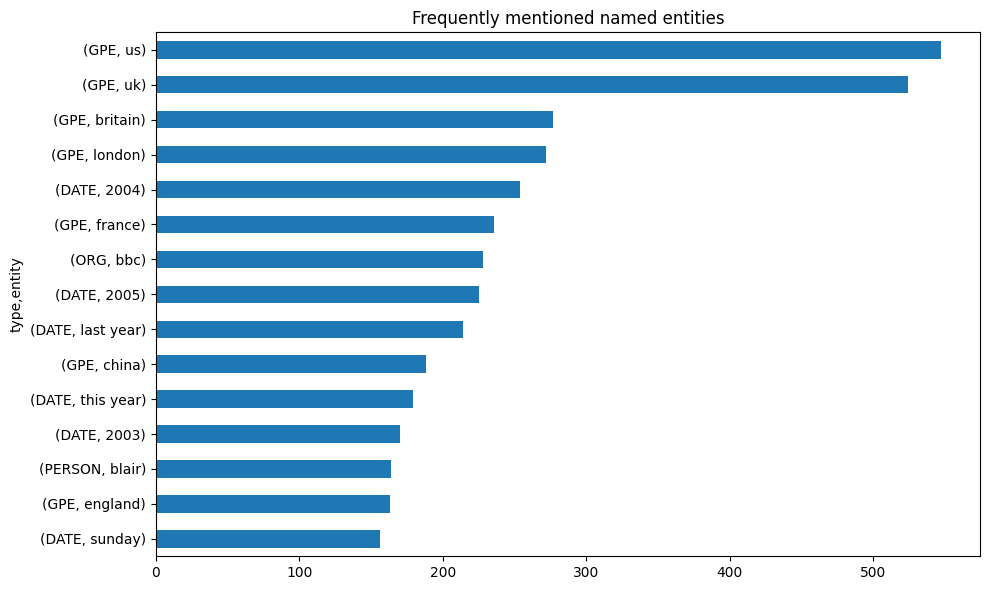

,entity_a,entity_b,cooccurring_articles
0,britain,uk,68
1,london,uk,65
2,uk,us,63
3,blair,tony blair,51
4,britain,tony blair,37
5,new york,us,31
6,britain,london,29
7,england,france,29
8,england,scotland,29
9,tony blair,uk,29


In [ ]:
entity_rows=[]
for article_id,category,doc in zip(df.article_id,df.category,docs):
    for ent in doc.ents:
        if ent.label_ in {'PERSON','ORG','GPE','DATE','MONEY'}:
            entity_rows.append({'article_id':article_id,'category':category,'entity':ent.text,'type':ent.label_})
entities=pd.DataFrame(entity_rows,columns=['article_id','category','entity','type'])
display(entities.groupby(['category','type']).size().unstack(fill_value=0))
if not entities.empty:
    top=entities.groupby(['type','entity']).size().sort_values(ascending=False).head(15)
    top.sort_values().plot.barh(figsize=(10,6),title='Frequently mentioned named entities');plt.tight_layout();plt.show()
    from itertools import combinations
    edges=Counter()
    for aid,g in entities[entities.type.isin(['PERSON','ORG','GPE'])].groupby('article_id'):
        names=sorted(set(g.entity.str.strip().str.lower()))[:30]
        edges.update(combinations(names,2))
    display(pd.DataFrame([{'entity_a':a,'entity_b':b,'cooccurring_articles':v} for (a,b),v in edges.most_common(15)]))

## 11 | Unified inference on previously unseen examples

The exact same fitted vectorizer and model used during training predict incoming articles. The system preserves full text for linguistic analysis and reports margins or probabilities only where mathematically meaningful. SVM decision margins are **not calibrated probabilities**.

In [ ]:
class NewsBotIntelligenceSystem:
    def __init__(self,model,nlp_pipeline,sentiment_analyzer):
        self.model=model;self.nlp=nlp_pipeline;self.sentiment=sentiment_analyzer
    def analyze(self,title,content):
        text=normalize_markup(str(title)+' '+str(content))
        if len(text)<30:raise ValueError('Provide article text, not only a short headline')
        doc=self.nlp(text)
        prediction=str(self.model.predict([text])[0])
        ents=[{'text':e.text,'type':e.label_} for e in doc.ents if e.label_ in {'PERSON','ORG','GPE','DATE','MONEY'}]
        tone=self.sentiment.polarity_scores(text)
        label='positive' if tone['compound']>=.05 else 'negative' if tone['compound']<=-.05 else 'neutral'
        result={'category':prediction,'sentiment':label,'sentiment_score':round(tone['compound'],3),'entities':ents[:25],'relations':extract_relations(doc,limit=8),'top_pos':Counter(t.pos_ for t in doc if t.is_alpha).most_common(5)}
        if hasattr(self.model,'predict_proba'):
            p=self.model.predict_proba([text])[0];result['model_class_probabilities']={str(k):round(float(v),3) for k,v in zip(self.model.classes_,p)}
        elif hasattr(self.model,'decision_function'):
            result['confidence_note']='Uncalibrated SVM margin; probability intentionally omitted'
        return result
bot=NewsBotIntelligenceSystem(selected_model,nlp,sia)
novel=[('Chipmaker invests in computing','A global semiconductor company announced a new research facility to develop processors for artificial intelligence applications. Engineers expect higher production capacity and new software partnerships over the next three years.'),('Local football club wins championship','The football team defeated its rival in a dramatic championship final on Sunday. Supporters celebrated as the captain scored twice and the coach praised the defense after the match.')]
for title,content in novel:
    print('ARTICLE:',title);print(json.dumps(bot.analyze(title,content),indent=2))
print('Note: examples are illustrative, and categories must be interpreted against the approved dataset labels.')

ARTICLE: Chipmaker invests in computing
{
  "category": "tech",
  "sentiment": "positive",
  "sentiment_score": 0.477,
  "entities": [
    {
      "text": "Chipmaker",
      "type": "ORG"
    },
    {
      "text": "the next three years",
      "type": "DATE"
    }
  ],
  "relations": [
    {
      "subject": "invests",
      "action": "announce",
      "object": "facility",
      "voice": "active"
    },
    {
      "subject": "Engineers",
      "action": "expect",
      "object": "capacity",
      "voice": "active"
    }
  ],
  "top_pos": [
    [
      "NOUN",
      14
    ],
    [
      "ADJ",
      6
    ],
    [
      "VERB",
      4
    ],
    [
      "ADP",
      3
    ],
    [
      "DET",
      3
    ]
  ],
  "confidence_note": "Uncalibrated SVM margin; probability intentionally omitted"
}
ARTICLE: Local football club wins championship
{
  "category": "sport",
  "sentiment": "positive",
  "sentiment_score": 0.949,
  "entities": [
    {
      "text": "Sunday",
      "type": "DA

## 12 | Evidence based findings and responsible interpretation

The notebook reports measured class counts, category vocabulary patterns, part of speech distributions, extraction coverage, sentiment distributions, named entities, training cross validation scores, held out classification accuracy and macro F1. Its final executable cell creates a compact metrics summary from the **actual** run. Review the resulting figures for at least three category specific observations before submitting.

**Methodological limitations:** The BBC corpus represents a particular publication and period rather than the full current news ecosystem. A lexical sentiment score is not equivalent to audience opinion. The small emotion dictionaries are exploratory keyword counts, not validated emotion classifiers. Cooccurrence of named entities does not establish a verified relationship, and subject verb object triples are syntactic approximations rather than complete semantic roles. Internal stratified evaluation is not evidence of robustness on current events or new publishers.

**Business value and governance:** NewsBot can support editorial classification, research routing and topic monitoring when a human can inspect errors. An operational pilot should evaluate manual correction rates, per category recall, false alerts, latency, privacy obligations, topic drift and operating costs. No return on investment is claimed without empirical measurements.

**References:** BBC News Classification competition, https://www.kaggle.com/competitions/learn-ai-bbc/data; Pedregosa et al. (2011), *Scikit learn: Machine Learning in Python*, JMLR 12, 2825 to 2830; Hutto and Gilbert (2014), *VADER*, ICWSM; Bird, Klein and Loper (2009), *Natural Language Processing with Python*, O'Reilly; spaCy documentation, https://spacy.io; Ganesan (2019), *Text Preprocessing for Machine Learning and NLP*, https://kavita-ganesan.com/text-preprocessing-tutorial/.


In [ ]:
# Automatically generated, reproducible summary based on this execution
summary = {
    'dataset_source': str(file_path),
    'n_articles': int(len(df)),
    'category_counts': {str(k): int(v) for k, v in counts.items()},
    'selected_model': str(selected_name),
    'cv_macro_f1': round(float(comparison.iloc[0]['cv_macro_f1']), 4),
    'held_out_accuracy': round(float(accuracy_score(y_test, y_pred)), 4),
    'held_out_macro_f1': round(float(f1_score(y_test, y_pred, average='macro')), 4),
    'named_entity_mentions': int(len(entities)),
    'mean_relations_per_article': round(float(df.relation_count.mean()), 3)
}
print(json.dumps(summary, indent=2))
with open('newsbot_metrics.json', 'w', encoding='utf-8') as f:
    json.dump(summary, f, indent=2)
print('Saved: newsbot_metrics.json')

{
  "dataset_source": "BBC News Train.csv",
  "n_articles": 1440,
  "category_counts": {
    "sport": 342,
    "business": 335,
    "politics": 266,
    "entertainment": 263,
    "tech": 234
  },
  "selected_model": "Linear SVM",
  "cv_macro_f1": 0.9694,
  "held_out_accuracy": 0.9653,
  "held_out_macro_f1": 0.9645,
  "named_entity_mentions": 27756,
  "mean_relations_per_article": 7.263
}
Saved: newsbot_metrics.json
